### 1. Environment setup and model loading

This section prepares the Google Colab environment for evaluating the trained autoencoder.

- **Import libraries:** Load TensorFlow for neural network inference, NumPy for numerical operations, and Matplotlib for visualization. Suppress Keras compatibility warnings.
- **Load repository:** Clone the TEM-IP GitHub repository containing the trained network and test datasets.
- **Define time gates:** Specify the measurement times corresponding to the TEM responses used by the network.
- **Load trained network:** Load the pretrained autoencoder (`IP_net.h5`) without recompiling it, preserving its trained architecture and weights for prediction.

In [3]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings("ignore", category=UserWarning, module=r"keras\..*")

!git clone https://github.com/rizwanasif/TEM-IP.git
%cd TEM-IP

t = np.array([1.24900e-05, 1.44900e-05, 1.64900e-05, 1.84900e-05, 2.04900e-05,
              2.29900e-05, 2.59900e-05, 2.94900e-05, 3.39900e-05, 3.99900e-05,
              4.74900e-05, 5.64900e-05, 6.79900e-05, 8.24900e-05, 1.01000e-04,
              1.24500e-04, 1.53500e-04, 1.90500e-04, 2.37000e-04, 2.95000e-04,
              3.68500e-04, 4.61000e-04, 5.77500e-04, 7.24000e-04, 9.08500e-04])
t = t[:-1]

autoencoder = tf.keras.models.load_model('IP_net.h5', compile = False)

fatal: destination path 'TEM-IP' already exists and is not an empty directory.
/content/TEM-IP


### 2. Data configuration, preprocessing, and model evaluation

This section defines the test datasets and reusable functions for preparing TEM responses, evaluating the trained autoencoder, and visualizing individual reconstructions.

- **Dataset configuration:** Specify the test files containing 1-, 3-, 5-, and 7-layer IP models and set the relative error threshold to 3%.
- **Data preprocessing:** Extract model parameters, filter TEM responses based on sign changes, and prepare logarithmic inputs for the network.
- **Model evaluation:** Calculate reconstruction errors and the percentage of predictions within the ±3% relative error threshold.
- **Reconstruction visualization:** Plot individual TEM responses, distinguishing positive and negative values, together with the autoencoder reconstruction and relative error as a function of measurement time.

In [4]:
#%% Files and settings

files = {
    "1 layer": ("out_1lay.txt", 2),
    "3 layers": ("out_3lay.txt", 3),
    "5 layers": ("out_5lay.txt", 5),
    "7 layers": ("out_7lay.txt", 7)
}

n_layers = {
    "1 layer": 1,
    "3 layers": 3,
    "5 layers": 5,
    "7 layers": 7,
}

perc = 3


#%% Preprocessing

def preprocess(file_path, n_layer):

    file_IP_halfspace = np.loadtxt(file_path)

    res_IP_halfspace = np.array(file_IP_halfspace[:, 0:n_layer])
    print(res_IP_halfspace.shape)
    phi_IP_halfspace = np.array(file_IP_halfspace[:, n_layer:2*n_layer])
    tau_IP_halfspace = np.array(file_IP_halfspace[:, 2*n_layer:3*n_layer])
    c_IP_halfspace = np.array(file_IP_halfspace[:, 3*n_layer:4*n_layer])
    thk_IP_halfspace = np.array(file_IP_halfspace[:, 4*n_layer:5*n_layer-1])
    dBdt_IP_halfspace = np.array(file_IP_halfspace[:, 5*n_layer-1:-1])

    dBdt_IP_flag_halfspace = dBdt_IP_halfspace.copy()
    dBdt_IP_flag_halfspace[dBdt_IP_halfspace >= 0] = 1
    dBdt_IP_flag_halfspace[dBdt_IP_halfspace < 0] = -1

    x_halfspace = np.log10(abs(dBdt_IP_halfspace))

    x_test = dBdt_IP_flag_halfspace
    x_test[x_test == 0] = np.nan

    x_test_dif = np.diff(x_test)
    x_test_dif_ = np.where(np.isnan(x_test_dif), 0, x_test_dif)
    x_test_dif_s = np.sum(abs(x_test_dif_), 1) <= 2
    x_test_dif_n_p = np.sum(x_test_dif_ == 2, 1) == 0
    x_test_dif_t = np.logical_and(x_test_dif_s, x_test_dif_n_p)

    x_test_ = x_halfspace[x_test_dif_t, :]
    x_test_dif_ = x_test_dif_[x_test_dif_t, :]

    x_test_dif__ = np.append(
        x_test_dif_,
        np.zeros((x_test_dif_.shape[0], 1)),
        axis=1
    )

    shifted = np.zeros(x_test_dif__.shape, dtype=x_test_dif__.dtype)
    shifted[:, 1:] = x_test_dif__[:, :-1]

    x_test_[x_test_dif__ != 0] = 0.
    x_test_[shifted != 0] = 0.

    dBdt_IP = dBdt_IP_halfspace[x_test_dif_t, :]

    return x_test_, dBdt_IP


#%% Prediction and relative error

def evaluate(x_test_, perc=3):


    decoded_imgs1_test = autoencoder.predict(x_test_).squeeze()
    x_test2 = 10**x_test_
    de_test2 = 10**decoded_imgs1_test

    x_test2_eval = x_test2.copy()
    x_test2_eval[x_test2_eval == 1] = np.nan

    rel_err_test = (de_test2 - x_test2_eval) / x_test2_eval * 100

    g_rel_test = rel_err_test.copy()
    g_rel_test[abs(rel_err_test) <= perc] = 1
    g_rel_test[abs(rel_err_test) > perc] = 0

    nancounts = np.sum(np.isnan(g_rel_test), axis=0)
    total_count = g_rel_test.shape[0] - nancounts

    per_test = np.nansum(g_rel_test, 0) / total_count
    total_acc = np.nansum(g_rel_test) / np.sum(total_count)

    return per_test, total_acc


def plot_reconstruction(t, dBdt_IP, x_test_, decoded_imgs1_test, idxx=0, font=12):

    plt.figure(constrained_layout=True, figsize=(3, 6))

    # Find positions of positive and negative values
    pos = dBdt_IP[idxx, :] >= 0
    neg = dBdt_IP[idxx, :] < 0

    reconstuct = decoded_imgs1_test[idxx, :].copy()
    reconstuct[x_test_[idxx, :] == 0] = np.nan

    # Prepare the data for line collection
    points = np.array([t, abs(dBdt_IP[idxx, :])]).T.reshape(-1, 1, 2)
    segments = np.concatenate([points[:-1], points[1:]], axis=1)

    colors = ['C0' if val > 0 else 'C1' for val in dBdt_IP[idxx, :]]

    lc = LineCollection(segments, colors=colors, linewidths=1)
    plt.gca().add_collection(lc)

    # Positive and negative responses
    plt.plot(t[pos], abs(dBdt_IP[idxx, :][pos]),
             '-o', color='C0', linewidth=1, label='Positive')

    plt.plot(t[neg], abs(dBdt_IP[idxx, :][neg]),
             '-o', color='C1', linewidth=1, label='Negative')

    # Reconstructed output
    plt.plot(t, 10**reconstuct,
             ':.', linewidth=2, color='k', label='Output')

    # Error legend
    plt.plot([], [], ':.', color='C2', label='Error')

    plt.legend(loc='best', fontsize=font)

    plt.xscale("log")
    plt.yscale("log")

    plt.xlabel('Time (s)', fontsize=font)
    plt.ylabel('dB/dt (V/Am$^{2}$)', fontsize=font)

    #plt.ylim([1e-13, 1e-7])
    plt.xlim([1e-5, 1e-3])

    plt.grid()
    plt.tick_params(axis='both', which='major', labelsize=font)
    plt.gca().set_aspect("equal")

    # Reconstruction error (secondary axis)
    ax2 = plt.twinx()

    rel_err_test = (
        (10**decoded_imgs1_test[idxx, :] - 10**x_test_[idxx, :])
        / 10**x_test_[idxx, :]
    ) * 100

    rel_err_test[x_test_[idxx, :] == 0] = np.nan

    ax2.plot(t, abs(rel_err_test), ':.', color='C2')

    ax2.set_ylim([-0.02, 10])
    ax2.set_yticks([0, 1.5, 3, 4.5, 6, 7.5, 9])
    ax2.set_ylabel('Reconstruction error (%)', fontsize=font)
    ax2.tick_params(axis='both', which='major', labelsize=font)

    plt.show()

### 3. Model evaluation across different IP models

This section evaluates the trained autoencoder using TEM responses generated from 1-, 3-, 5-, and 7-layer IP models.

- **Run evaluation:** Preprocess each dataset and pass the TEM responses through the trained autoencoder.
- **Calculate accuracy:** Determine the percentage of reconstructed values within the ±3% relative error threshold for each time gate and across all valid data points.
- **Compare model performance:** Store the accuracy results for each dataset and plot them against measurement time.
- **Visualize results:** Compare reconstruction accuracy across different numbers of layers to assess how subsurface model complexity affects network performance.


1 layer
(39996, 2)
1102/1102 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step
Total accuracy: 0.993097871287969

3 layers
(9999, 3)
250/250 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step
Total accuracy: 0.9874087707726025

5 layers
(9999, 5)
245/245 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step
Total accuracy: 0.9790896976131919

7 layers
(9999, 7)
243/243 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step
Total accuracy: 0.9732060818201707


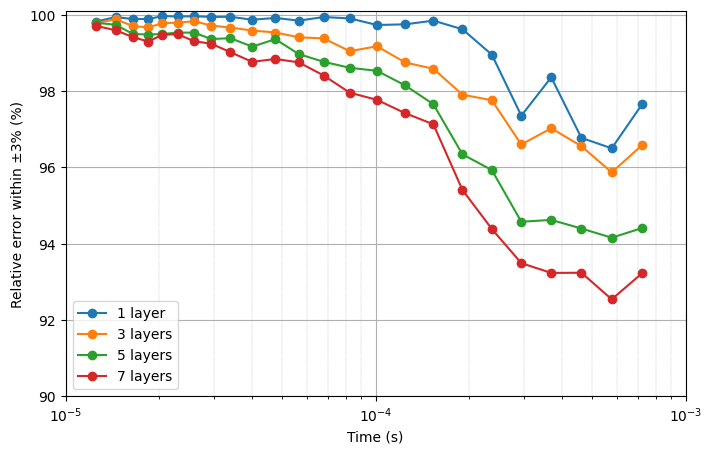

In [5]:
#%% Run all datasets

results = {}

for label, (file_path, n_layer) in files.items():

    print(f"\n{label}")

    x_test_, dBdt_IP = preprocess(file_path, n_layer)

    per_test, total_acc = evaluate(x_test_, perc)

    results[label] = per_test

    print("Total accuracy:", total_acc)


#%% Plot results

plt.figure(figsize=(8, 5))

for label, per_test in results.items():
    plt.semilogx(t, per_test * 100, '-o', label=label)

plt.xlabel('Time (s)')
plt.ylabel(f'Relative error within ±{perc}% (%)')
plt.xlim([1e-5, 1e-3])
plt.ylim([90, 100.1])

plt.grid()
plt.grid(which='minor', linestyle=':', linewidth='0.3', color='gray')
plt.legend()
plt.show()

### 4. Visualizing individual TEM response reconstructions

This section visualizes the autoencoder reconstruction for a selected TEM response.

- **Select dataset:** Choose the subsurface model (1, 3, 5, or 7 layers) and an individual TEM response using its sample index (`idxx`).
- **Preprocess input:** Prepare the selected dataset using the same preprocessing procedure applied during model evaluation.
- **Run prediction:** Pass the preprocessed TEM responses through the trained autoencoder.
- **Visualize reconstruction:** Compare the original TEM response with the reconstructed output and display the relative reconstruction error as a function of measurement time.

(39996, 2)


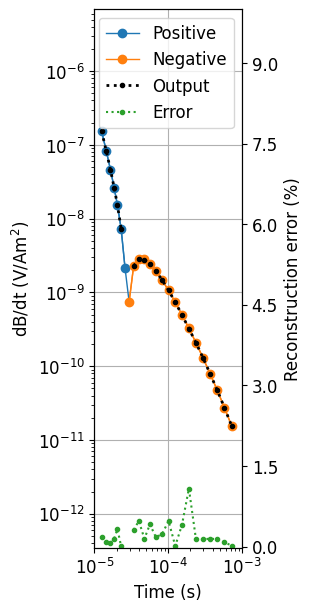

In [18]:
label = "1 layer"
idxx = 7

file_path, n_layer = files[label]

x_test_, dBdt_IP = preprocess(file_path, n_layer)
decoded_imgs1_test = autoencoder.predict(x_test_, verbose=0).reshape(x_test_.shape)

plot_reconstruction(t, dBdt_IP, x_test_, decoded_imgs1_test, idxx)

### 5. Evaluating network robustness to noisy TEM responses

This section investigates how the trained autoencoder performs when selected time gates are affected by noise.

- **Select dataset:** Choose a subsurface model and an individual TEM response.
- **Introduce noise:** Artificially modify the amplitudes at time gates 20 and 21 to simulate measurement errors.
- **Prepare noisy input:** Apply the corresponding modifications in logarithmic space while preserving masked values.
- **Run prediction:** Pass the noisy TEM responses through the trained autoencoder.
- **Visualize reconstruction:** Compare the noisy input with the reconstructed response and evaluate the relative reconstruction error across measurement times.

(39996, 2)


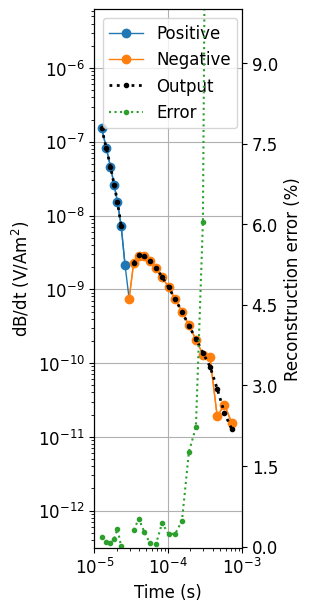

In [19]:
label = "1 layer"
idxx = 7

file_path, n_layer = files[label]

# Original input
x_test_, dBdt_IP = preprocess(file_path, n_layer)

# Add noise
x_test_noisy = x_test_.copy()
dBdt_IP_noisy = dBdt_IP.copy()

dBdt_IP_noisy[:, 20] *= 1.50
dBdt_IP_noisy[:, 21] *= 0.40

# Update network input (log scale)
x_test_noisy[:, 20] += np.log10(1.50)
x_test_noisy[:, 21] += np.log10(0.50)

# Preserve masked values
x_test_noisy[x_test_ == 0] = 0

# Run network
decoded_imgs1_test = autoencoder.predict(
    x_test_noisy, verbose=0
).reshape(x_test_noisy.shape)

# Plot
plot_reconstruction(
    t, dBdt_IP_noisy, x_test_noisy, decoded_imgs1_test, idxx
)

### 6. Evaluating network reconstruction with missing time gates

This section investigates the ability of the trained autoencoder to reconstruct TEM responses when late-time measurements are unavailable.

- **Select dataset:** Choose a subsurface model and an individual TEM response.
- **Remove late-time data:** Set the input values from time gate 20 onwards to zero, simulating missing measurements.
- **Run prediction:** Pass the truncated TEM response through the trained autoencoder.
- **Visualize reconstruction:** Display only the original measurements provided to the network and compare them with the reconstructed response.
- **Assess performance:** Examine the network's ability to recover the missing late-time response from the available early-time measurements.

(39996, 2)


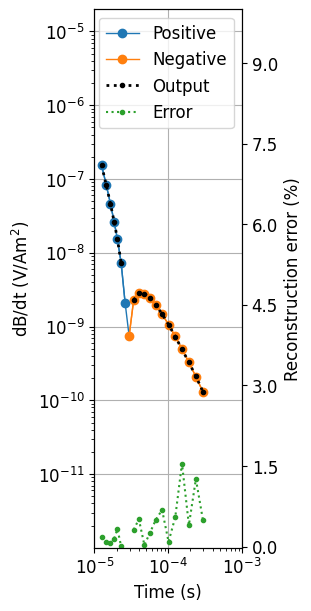

In [22]:
label = "1 layer"
idxx = 7

file_path, n_layer = files[label]

x_test_, dBdt_IP = preprocess(file_path, n_layer)

# Set input from gate 20 onwards to zero
x_test_noisy = x_test_.copy()
x_test_noisy[:, 20:] = 0

# Run network
decoded_imgs1_test = autoencoder.predict(
    x_test_noisy, verbose=0
).reshape(x_test_noisy.shape)

# Show only the original data used by the network
dBdt_IP_plot = dBdt_IP.copy()
dBdt_IP_plot[:, 20:] = np.nan

# Plot
plot_reconstruction(
    t, dBdt_IP_plot, x_test_noisy, decoded_imgs1_test, idxx
)